# Machine Learning-Based Remaining Useful Life Prediction of Aircraft Turbofan Engines



## 1. Introduction

Aircraft engines operate under high temperatures, pressure, and continuous mechanical stress. Over time, these conditions can cause engine components to wear out and their performance to degrade. Predicting when an engine may require maintenance is important for improving safety, reducing unexpected failures, and planning maintenance activities.

Remaining Useful Life (RUL) refers to the estimated number of operating cycles an engine can continue to operate before reaching the end of its useful life.

In this case study, we use Machine Learning to predict the remaining useful life of aircraft turbofan engines based on their operating conditions and sensor measurements. The project uses the NASA C-MAPSS FD001 dataset and a Random Forest Regression model.

The model learns patterns from historical engine data and uses them to estimate RUL. An interactive application is also developed using Gradio, allowing users to explore RUL predictions using engine sensor readings.

### Approach

The project uses a Random Forest Regression model to learn patterns from historical engine data and estimate RUL. An interactive application is also developed using Gradio to demonstrate predictions based on engine sensor readings.


### 1. Uploading the Dataset
The dataset used in this project is the **NASA C-MAPSS (Commercial Modular Aero-Propulsion System Simulation) FD001 dataset**, provided by NASA. It contains simulated turbofan engine run-to-failure data, including operating settings and sensor measurements collected over multiple operating cycles.

Dataset source: [NASA Prognostics Center of Excellence Data Repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/)


First, we upload the dataset files required for our project into Google Colab.

- `from google.colab import files` allows us to use Google Colab's file upload feature.
- `files.upload()` opens a file picker so we can select and upload files from our computer.
- The uploaded files are stored in the `uploaded` variable.

These files will be used in the following steps to load and analyze the aircraft engine data.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving CMAPSSData.zip to CMAPSSData.zip



### 2. Extracting the Dataset

The NASA C-MAPSS dataset was uploaded as a ZIP file named `CMAPSSData.zip`. Before using the data, we need to extract its contents into a folder so that we can access the individual dataset files.

- `zipfile` is used to open and extract the ZIP file.
- `os` is used to list the files available in the extracted folder.
- `extractall()` extracts the contents into the `CMAPSSData` folder.
- `os.listdir()` displays the extracted files to verify that the dataset is available.

This step prepares the dataset files for loading and further analysis.


In [ ]:
import zipfile
import os

zip_file = "CMAPSSData.zip"
extract_folder = "CMAPSSData"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Dataset extracted successfully!")
print(os.listdir(extract_folder))

Dataset extracted successfully!
['test_FD002.txt', 'train_FD004.txt', 'test_FD004.txt', 'RUL_FD004.txt', 'Damage Propagation Modeling.pdf', 'train_FD003.txt', 'test_FD001.txt', 'RUL_FD003.txt', 'test_FD003.txt', 'RUL_FD001.txt', 'RUL_FD002.txt', 'readme.txt', 'train_FD001.txt', 'train_FD002.txt']


### 3. Loading and Understanding the Training Data

The training file is loaded into a Pandas DataFrame named `df`. We assign readable column names to the engine ID, operating cycle, three operating settings, and 21 sensor measurements. Each row represents one engine at one operating cycle.

The next cell checks the dataset's dimensions, the number of unique engines, the number of recorded cycles, the available columns, and whether any values are missing. These checks help us understand the data before calculating RUL or training a model.


In [ ]:
import pandas as pd

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

file_path = "CMAPSSData/train_FD001.txt"

df = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (20631, 26)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [ ]:
print("Dataset dimensions:", df.shape)

print("\nNumber of engines:", df["engine_id"].nunique())

print("\nTotal operating cycles:", df["cycle"].count())

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum().sum())

Dataset dimensions: (20631, 26)

Number of engines: 100

Total operating cycles: 20631

Columns:
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']

Missing values:
0


### 4. Calculating Remaining Useful Life (RUL)

The training data records each engine over multiple operating cycles until its simulated run ends. For each engine, we find its final recorded cycle. The RUL for an earlier row is calculated as:

**RUL = final recorded cycle − current cycle**

For example, if an engine's last recorded cycle is 150, then a row at cycle 100 has an RUL of 50 cycles. This creates the target value the machine-learning model will learn to predict.


In [ ]:
# Find the last recorded cycle for each engine
last_cycle = df.groupby("engine_id")["cycle"].max()

# Add the correct RUL value to every training row
df["RUL"] = (
    df["engine_id"].map(last_cycle) - df["cycle"]
)

# Check the result for Engine 1
display(
    df[df["engine_id"] == 1][
        ["engine_id", "cycle", "RUL"]
    ].head(10)
)

print("Updated dataset shape:", df.shape)

,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


Updated dataset shape: (20631, 27)


### 5. Exploring Sensor Readings

Before training the model, we visualize selected sensor readings across operating cycles. The plots first examine Engine 1, then show the selected sensors individually, and finally compare the same sensors across several engines.

These visualizations help us see how sensor values change over time and whether different engines show similar or different patterns. Not every sensor necessarily changes clearly as an engine ages, so the plots are exploratory rather than proof of a specific failure cause.


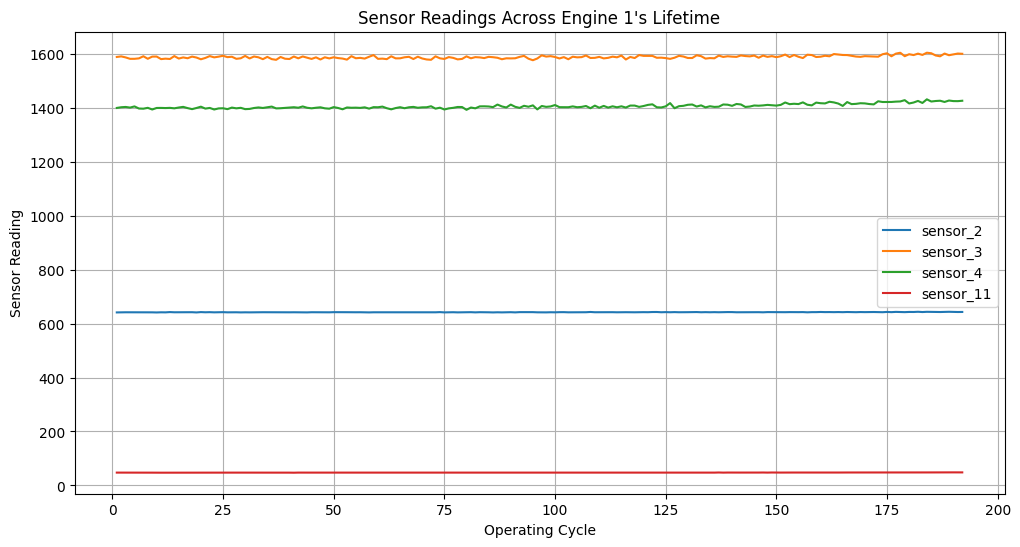

In [ ]:
import matplotlib.pyplot as plt

# Select Engine 1
engine_1 = df[df["engine_id"] == 1]

# Plot selected sensor readings over operating cycles
sensors = ["sensor_2", "sensor_3", "sensor_4", "sensor_11"]

plt.figure(figsize=(12, 6))

for sensor in sensors:
    plt.plot(
        engine_1["cycle"],
        engine_1[sensor],
        label=sensor
    )

plt.xlabel("Operating Cycle")
plt.ylabel("Sensor Reading")
plt.title("Sensor Readings Across Engine 1's Lifetime")
plt.legend()
plt.grid(True)
plt.show()

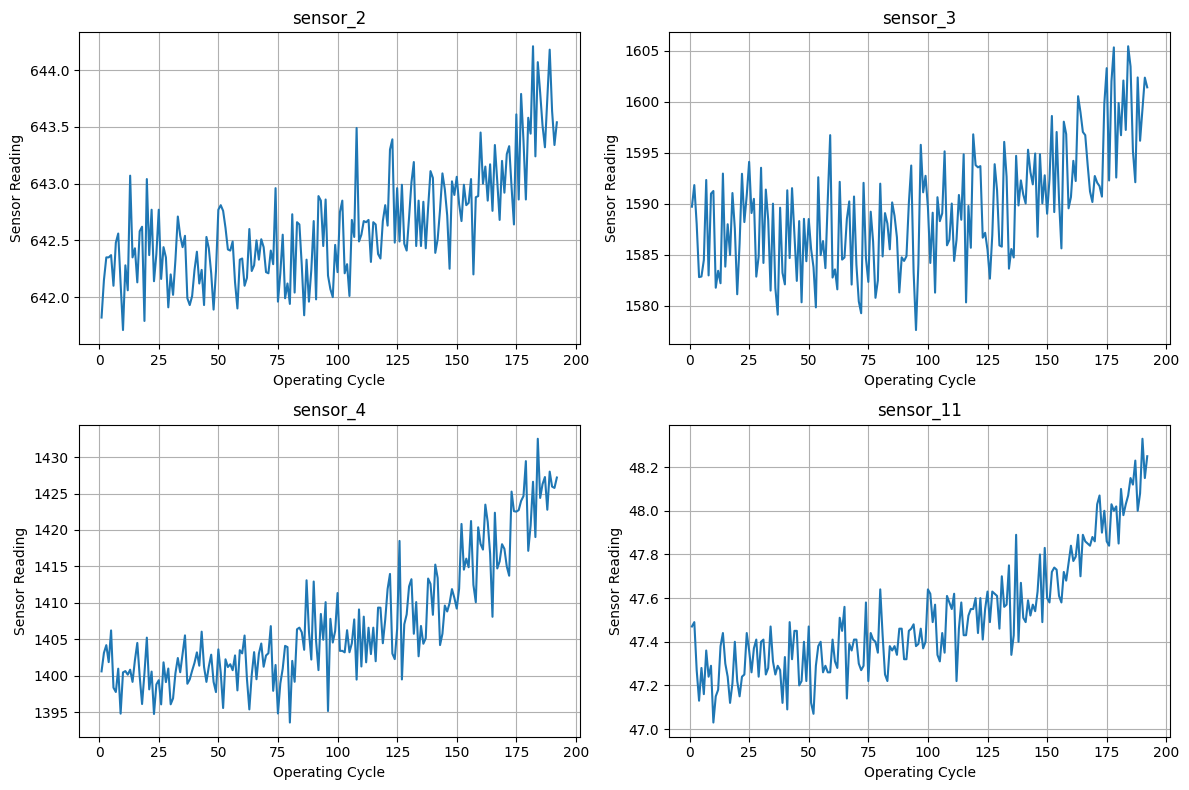

In [ ]:
import matplotlib.pyplot as plt

sensors = ["sensor_2", "sensor_3", "sensor_4", "sensor_11"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, sensor in zip(axes.flatten(), sensors):
    ax.plot(engine_1["cycle"], engine_1[sensor])
    ax.set_title(sensor)
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor Reading")
    ax.grid(True)

plt.tight_layout()
plt.show()

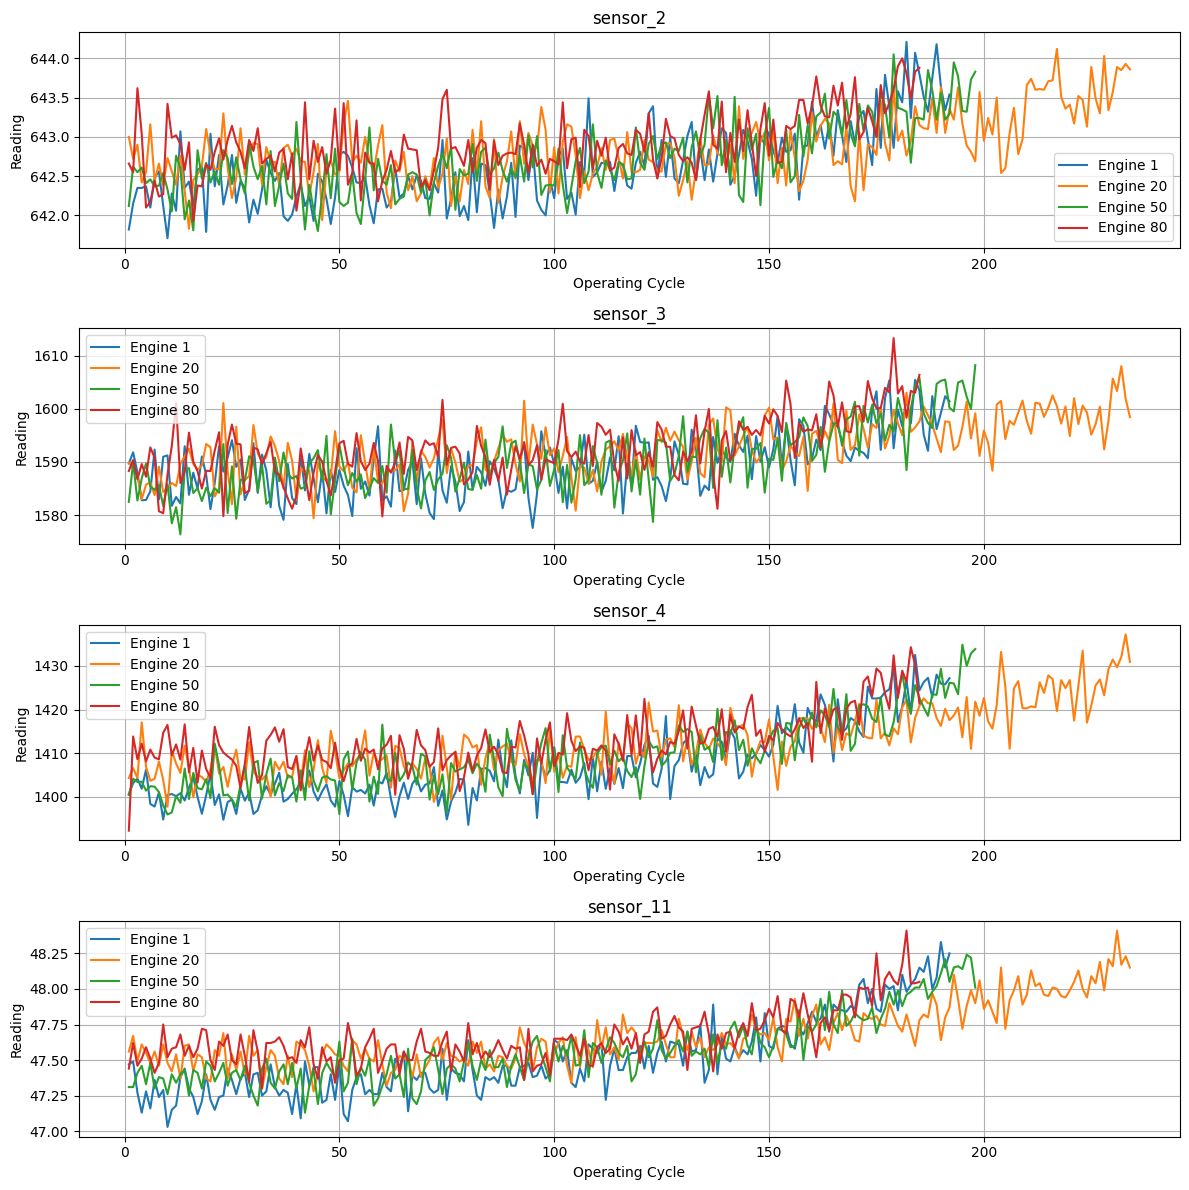

In [ ]:
import matplotlib.pyplot as plt

engines = [1, 20, 50, 80]
sensors = ["sensor_2", "sensor_3", "sensor_4", "sensor_11"]

fig, axes = plt.subplots(4, 1, figsize=(12, 12))

for ax, sensor in zip(axes, sensors):
    for engine_id in engines:
        engine_data = df[df["engine_id"] == engine_id]

        ax.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {engine_id}"
        )

    ax.set_title(sensor)
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Reading")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 6. Limiting the RUL Target to 125 Cycles

Some engines have a long period in which their RUL is high and their condition may not yet show a clear degradation pattern. To reduce the influence of very large target values, this step caps the model's training target at **125 cycles**.

The original values are preserved in `RUL_raw`, while `RUL` contains the capped values used for training. Values above 125 become 125; values at or below 125 remain unchanged. The same cap is applied when preparing the official test labels later.


In [ ]:
# Preserve our original RUL values
df["RUL_raw"] = df["RUL"]

# Create a capped target for our first model
df["RUL"] = df["RUL_raw"].clip(upper=125)

# Display the results for Engine 1
display(
    df[df["engine_id"] == 1][
        ["engine_id", "cycle", "RUL_raw", "RUL"]
    ].head(10)
)

print("Maximum capped RUL:", df["RUL"].max())

,engine_id,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


Maximum capped RUL: 125


In [ ]:
print(df.loc[0, ["engine_id", "cycle", "RUL_raw", "RUL"]])

print("\nMaximum raw RUL:", df["RUL_raw"].max())
print("Maximum capped RUL:", df["RUL"].max())

display(
    df[["engine_id", "cycle", "RUL_raw", "RUL"]].head(10)
)

engine_id      1.0
cycle          1.0
RUL_raw      191.0
RUL          125.0
Name: 0, dtype: float64

Maximum raw RUL: 361
Maximum capped RUL: 125


,engine_id,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125
5,1,6,186,125
6,1,7,185,125
7,1,8,184,125
8,1,9,183,125
9,1,10,182,125


### 7. Selecting Features and Splitting the Data

The model uses 24 input features: three operating settings and 21 sensor readings. The engine ID and cycle number are not included as input features in this model. The target variable, `y`, is the capped RUL.

The data is split by **engine ID**, not randomly by individual rows. This keeps the rows belonging to an engine together, so the same engine does not appear in both the training and validation sets. This is important because rows from one engine are related to one another; splitting them across both sets could make validation results overly optimistic.


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Select input features
feature_columns = [
    col for col in df.columns
    if col.startswith("setting_") or col.startswith("sensor_")
]

X = df[feature_columns]
y = df["RUL"]
groups = df["engine_id"]

# Split by engine to prevent data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

print("Number of input features:", len(feature_columns))
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Training engines:", groups.iloc[train_idx].nunique())
print("Validation engines:", groups.iloc[val_idx].nunique())

Number of input features: 24
Training rows: 16561
Validation rows: 4070
Training engines: 80
Validation engines: 20


### 8. Training the Baseline Random Forest Model

A Random Forest Regressor is trained to estimate RUL from the 24 selected features. A random forest combines predictions from many decision trees, which can learn non-linear relationships between operating settings, sensor readings, and RUL.

Here, `n_estimators=200` means the model uses 200 trees. After fitting the model on the training data, we predict RUL for the validation engines.

Two error metrics are printed:
- **MAE (Mean Absolute Error):** the average absolute difference between predicted and actual RUL, measured in cycles.
- **RMSE (Root Mean Squared Error):** also measures error in cycles, but gives larger errors more weight.

Lower values generally indicate more accurate predictions on the evaluated data.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict RUL for unseen engines
y_pred = rf_model.predict(X_val)

# Evaluate predictions
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("Random Forest Model Results")
print("---------------------------")
print(f"MAE:  {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")

Random Forest Model Results
---------------------------
MAE:  12.56 cycles
RMSE: 17.17 cycles


### 9. Comparing Actual and Predicted RUL

This scatter plot compares each validation row's actual RUL with the model's predicted RUL. The dashed diagonal represents perfect predictions: points close to this line have predictions close to the actual values.

Points farther from the line indicate larger prediction errors. The plot provides a visual check alongside MAE and RMSE; it does not replace those numerical metrics.


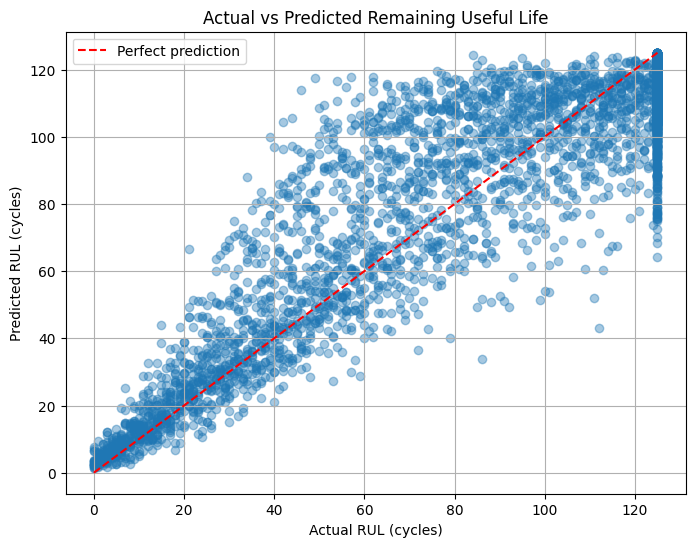

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_val, y_pred, alpha=0.4)

# Perfect prediction reference line
plt.plot([0, 125], [0, 125], "r--", label="Perfect prediction")

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs Predicted Remaining Useful Life")
plt.legend()
plt.grid(True)
plt.show()

### 10. Understanding Feature Importance

Random Forest provides a feature-importance score for each input. This cell ranks the 24 features and displays the ten highest scores.

A higher score means the feature contributed more to the model's tree-based splits according to this importance measure. It does **not** prove that the feature causes engine degradation, and importance values can be affected by correlations among sensors.


Top 10 most important features:


,Importance
sensor_11,0.565864
sensor_9,0.127956
sensor_4,0.077444
sensor_12,0.034072
sensor_14,0.028445
sensor_7,0.028050
sensor_15,0.022230
sensor_21,0.017772
sensor_2,0.016775
sensor_3,0.016430


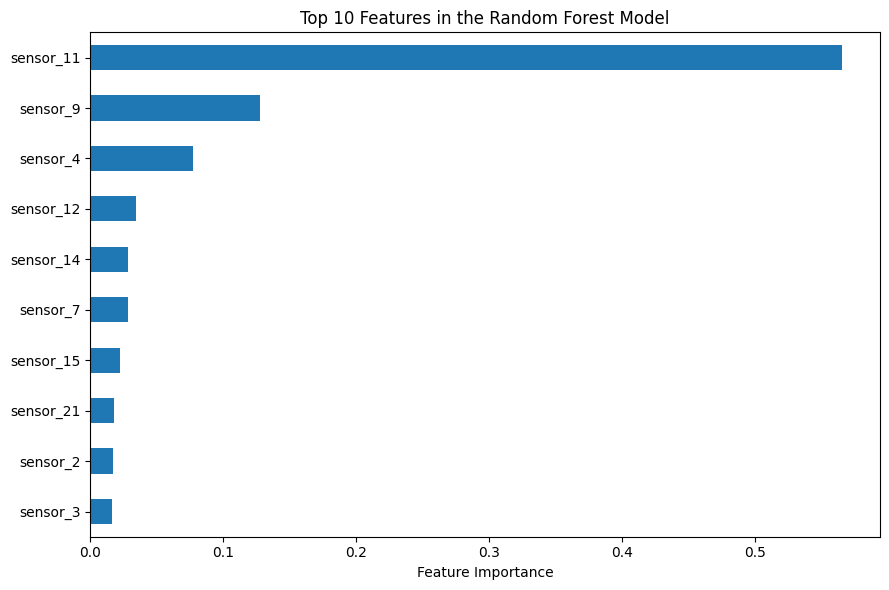

In [ ]:
import pandas as pd

importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_columns
).sort_values(ascending=False)

print("Top 10 most important features:")
display(importance.head(10).to_frame("Importance"))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title="Top 10 Features in the Random Forest Model"
)

plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

### 11. Examining Prediction Errors

This section compares actual and predicted RUL values for the validation set and calculates the absolute error for each prediction. It then groups results into RUL ranges (0–25, 26–50, 51–75, 76–100, and 101–125 cycles).

The table reports the number of samples and the mean absolute error in each range. This helps identify whether the model performs differently at different stages of an engine's remaining life.


In [ ]:
import pandas as pd
import numpy as np

# Create a table of actual and predicted RUL
evaluation = pd.DataFrame({
    "Actual_RUL": y_val,
    "Predicted_RUL": y_pred
})

# Calculate prediction error
evaluation["Absolute_Error"] = abs(
    evaluation["Actual_RUL"] - evaluation["Predicted_RUL"]
)

# Group results by actual RUL range
evaluation["RUL_Range"] = pd.cut(
    evaluation["Actual_RUL"],
    bins=[-1, 25, 50, 75, 100, 125],
    labels=["0–25", "26–50", "51–75", "76–100", "101–125"]
)

# Calculate error for each range
error_analysis = evaluation.groupby(
    "RUL_Range", observed=False
).agg(
    Samples=("Absolute_Error", "count"),
    MAE=("Absolute_Error", "mean")
).round(2)

display(error_analysis)

,Samples,MAE
RUL_Range,,
0–25,520,5.33
26–50,500,14.47
51–75,500,20.01
76–100,500,16.46
101–125,2050,11.15


In [ ]:
# Calculate signed prediction error
evaluation["Signed_Error"] = (
    evaluation["Predicted_RUL"] - evaluation["Actual_RUL"]
)

bias_analysis = evaluation.groupby(
    "RUL_Range", observed=False
).agg(
    Mean_Prediction_Error=("Signed_Error", "mean"),
    Mean_Absolute_Error=("Absolute_Error", "mean")
).round(2)

display(bias_analysis)

,Mean_Prediction_Error,Mean_Absolute_Error
RUL_Range,,
0–25,3.89,5.33
26–50,10.66,14.47
51–75,14.55,20.01
76–100,8.25,16.46
101–125,-10.15,11.15


### 13. Training and Evaluating the Model

This cell trains a Random Forest with a selected configuration: 100 trees, maximum depth of 15, and a minimum of two samples per leaf. It then evaluates that model on the same validation split using MAE and RMSE.

Compare these values with the baseline results above to see whether the chosen configuration improves validation performance. In this notebook's recorded run, the tuned model's validation results were approximately **12.36 cycles MAE** and **17.08 cycles RMSE**.


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

tuned_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

tuned_model.fit(X_train, y_train)

tuned_pred = tuned_model.predict(X_val)

print("Tuned Model MAE:",
      round(mean_absolute_error(y_val, tuned_pred), 2))

print("Tuned Model RMSE:",
      round(np.sqrt(mean_squared_error(y_val, tuned_pred)), 2))


Tuned Model MAE: 12.36
Tuned Model RMSE: 17.08


### 14. Saving the Model and Feature List

The trained model is saved as `aircraft_rul_random_forest.pkl`, and the ordered list of input feature names is saved as `aircraft_rul_features.pkl`.

Saving both is useful because a future prediction must use the same trained model and the same feature names in the same order. These files can be loaded later without retraining the model, provided the required Python libraries and compatible data are available.


In [ ]:

import joblib

joblib.dump(tuned_model, "aircraft_rul_random_forest.pkl")

joblib.dump(
    feature_columns,
    "aircraft_rul_features.pkl"
)

print("Model and feature list saved successfully!")


Model and feature list saved successfully!


In [ ]:

import os

data_folder = "/content/CMAPSSData"

print("Test dataset exists:",
      os.path.exists(f"{data_folder}/test_FD001.txt"))

print("Official RUL file exists:",
      os.path.exists(f"{data_folder}/RUL_FD001.txt"))


Test dataset exists: True
Official RUL file exists: True


### 15. Loading the Official Test Data

The official NASA FD001 test file contains the later recorded portions of 100 engines. The corresponding `RUL_FD001.txt` file provides the true remaining useful life values for those engines at the end of the supplied test sequences.

We load both files and give the test columns the same names used during training. Keeping the training and test feature names consistent helps us pass the correct inputs to the model.


In [ ]:

import pandas as pd
import numpy as np

# Load NASA's official test dataset
test_df = pd.read_csv(
    "/content/CMAPSSData/test_FD001.txt",
    sep=r"\s+",
    header=None
)

# Remove empty columns, if present
test_df = test_df.dropna(axis=1, how="all")

# Assign column names
columns = [
    "engine_id", "cycle",
    "setting_1", "setting_2", "setting_3"
] + [f"sensor_{i}" for i in range(1, 22)]

test_df.columns = columns

# Load official RUL values
true_rul = pd.read_csv(
    "/content/CMAPSSData/RUL_FD001.txt",
    sep=r"\s+",
    header=None
).iloc[:, 0]

print("Test dataset shape:", test_df.shape)
print("Number of test engines:", test_df["engine_id"].nunique())
print("Number of official RUL values:", len(true_rul))

display(test_df.head())


Test dataset shape: (13096, 26)
Number of test engines: 100
Number of official RUL values: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


### 16. Predicting RUL for the Official Test Engines

For each test engine, we select its last recorded row because the goal is to estimate RUL at the end of the available test sequence. We then select the same 24 features used during training and pass them to the chosen model.

The official RUL values are capped at 125 to match the target treatment used during training. The resulting table shows each engine's actual RUL, predicted RUL, and absolute prediction error.


In [ ]:

# Get the last recorded row for each test engine
test_last = (
    test_df.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

# Select the same 24 features used during training
X_test_final = test_last[feature_columns]

# Predict remaining useful life
test_predictions = tuned_model.predict(X_test_final)

# The official RUL values correspond to engines 1–100
actual_rul = true_rul.to_numpy()

# Apply the same cap used during training
actual_rul_capped = np.clip(actual_rul, 0, 125)

# Create a results table
test_results = pd.DataFrame({
    "Engine_ID": test_last["engine_id"],
    "Actual_RUL": actual_rul_capped,
    "Predicted_RUL": test_predictions
})

test_results["Absolute_Error"] = abs(
    test_results["Actual_RUL"] - test_results["Predicted_RUL"]
)

display(test_results.head(10))


,Engine_ID,Actual_RUL,Predicted_RUL,Absolute_Error
0,1,112,118.076095,6.076095
1,2,98,117.514019,19.514019
2,3,69,65.792155,3.207845
3,4,82,97.937529,15.937529
4,5,91,98.877669,7.877669
5,6,93,100.597949,7.597949
6,7,91,104.497794,13.497794
7,8,95,100.306161,5.306161
8,9,111,107.846345,3.153655
9,10,96,107.749177,11.749177


### 17. Evaluating on the Official Test Set

This cell calculates MAE and RMSE by comparing the predictions for the 100 official test engines with the corresponding capped NASA RUL labels.

These metrics provide a final evaluation on the separate official test set, which was not used to fit the model. In the recorded run, the results were approximately **11.81 cycles MAE** and **16.71 cycles RMSE**. Results can differ if the data split, model settings, or notebook execution changes.


In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

test_mae = mean_absolute_error(
    test_results["Actual_RUL"],
    test_results["Predicted_RUL"]
)

test_rmse = np.sqrt(mean_squared_error(
    test_results["Actual_RUL"],
    test_results["Predicted_RUL"]
))

print("Official Test MAE:", round(test_mae, 2), "cycles")
print("Official Test RMSE:", round(test_rmse, 2), "cycles")


Official Test MAE: 11.81 cycles
Official Test RMSE: 16.71 cycles


### 18. Creating a Reusable Prediction Function

The `predict_engine_rul()` function accepts an engine ID, finds that engine's last recorded test row, selects the required features, and returns the model's predicted RUL. If the engine ID is not available, it returns a message instead.

The example call tests the function for Engine 1. Its output is an estimate based on the available sensor readings, not a guarantee of the engine's actual remaining operating life.


In [ ]:

def predict_engine_rul(engine_id):
    # Select the chosen engine's last recorded cycle
    engine_data = test_last[
        test_last["engine_id"] == engine_id
    ]

    if engine_data.empty:
        return "Engine not found."

    # Select the same features used during training
    input_data = engine_data[feature_columns]

    # Predict remaining useful life
    prediction = tuned_model.predict(input_data)[0]

    return round(float(np.clip(prediction, 0, 125)), 1)


# Test the prediction function
print("Predicted RUL for Engine 1:",
      predict_engine_rul(1), "cycles")


Predicted RUL for Engine 1: 118.1 cycles


### 19. Installing Gradio for the Interactive Demo

Gradio is used to create a simple interface for interacting with the trained model. This installation cell prepares the notebook environment for the interface cells below. In a fresh runtime, the package may need to be installed again.


In [ ]:

!pip -q install gradio


### 20. Interactive App 1: Select an Engine

This Gradio interface lets a user select an engine ID from a dropdown. It displays the model's predicted RUL, the official capped RUL from the test labels, and the absolute error for that engine.

The app uses the test results already calculated in the notebook. The `share=True` option can create a temporary public link, so the link should not be treated as a permanent deployment.


In [ ]:

import gradio as gr

def show_prediction(engine_id):
    engine_id = int(engine_id)

    engine_row = test_results[
        test_results["Engine_ID"] == engine_id
    ].iloc[0]

    predicted = engine_row["Predicted_RUL"]
    actual = engine_row["Actual_RUL"]

    return (
        f"Engine ID: {engine_id}\n"
        f"Predicted Remaining Useful Life: {predicted:.1f} cycles\n"
        f"Official Actual RUL (capped): {actual} cycles\n"
        f"Absolute Error: {abs(actual - predicted):.1f} cycles"
    )

demo = gr.Interface(
    fn=show_prediction,
    inputs=gr.Dropdown(
        choices=list(range(1, 101)),
        value=1,
        label="Select Engine ID"
    ),
    outputs=gr.Textbox(label="Prediction Results", lines=4),
    title="Aircraft Engine Remaining Useful Life Prediction",
    description=(
        "Select a test engine to view its Random Forest RUL prediction. "
        "This demonstration uses NASA C-MAPSS FD001 test data."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/29 10:00:31 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>

### 21. Inspecting the Input Sensor Readings

Before building the next interface, this cell displays the 24 input feature values from the last recorded row for Engine 1. These are the operating settings and sensor readings that the model receives for that engine's prediction.

This provides a concrete example of the data used as model input.


In [ ]:

import pandas as pd
import numpy as np

# Show the available engine cycles
print("Number of engines:", test_df["engine_id"].nunique())
print("Number of recorded rows:", len(test_df))

# Select one engine and inspect its sensor readings
sample_engine = test_df[test_df["engine_id"] == 1]
sample_row = sample_engine.iloc[-1]

display(sample_row[feature_columns].to_frame("Input Value"))


Number of engines: 100
Number of recorded rows: 13096


,Input Value
setting_1,-0.0006
setting_2,0.0004
setting_3,100.0000
sensor_1,518.6700
sensor_2,642.5800
sensor_3,1581.2200
sensor_4,1398.9100
sensor_5,14.6200
sensor_6,21.6100
sensor_7,554.4200


### 22. Interactive App 2: Prediction with Sensor Readings

This interface lets the user choose an engine and view both its latest available feature readings and its predicted RUL. The prediction uses the selected engine's last recorded row from the official test data.

Showing the readings alongside the result makes the prediction process easier to inspect. The readings are model inputs; they should not be interpreted as individual explanations for why the model produced its estimate.


In [ ]:

import gradio as gr
import pandas as pd
import numpy as np

def predict_from_engine(engine_id):
    engine_id = int(engine_id)

    # Get the selected engine's last recorded cycle
    row = test_last[
        test_last["engine_id"] == engine_id
    ].iloc[0]

    # Prepare the 24 features in the correct order
    input_data = pd.DataFrame(
        [row[feature_columns].to_dict()],
        columns=feature_columns
    )

    # Predict RUL
    prediction = float(tuned_model.predict(input_data)[0])
    prediction = np.clip(prediction, 0, 125)

    # Display the input sensor readings
    readings = input_data.T.reset_index()
    readings.columns = ["Feature", "Input Value"]

    return (
        readings,
        f"Engine {engine_id}",
        f"{prediction:.1f} cycles"
    )

with gr.Blocks() as demo:
    gr.Markdown("# Aircraft Engine RUL Prediction")
    gr.Markdown(
        "Select an engine to view its latest recorded sensor "
        "readings and predict its remaining useful life."
    )

    engine_choice = gr.Dropdown(
        choices=list(range(1, 101)),
        value=1,
        label="Engine ID"
    )

    predict_button = gr.Button("Predict Remaining Useful Life")

    engine_label = gr.Textbox(label="Selected Engine")
    prediction_output = gr.Textbox(label="Predicted RUL")
    sensor_table = gr.Dataframe(label="Input Sensor Readings")

    predict_button.click(
        fn=predict_from_engine,
        inputs=engine_choice,
        outputs=[sensor_table, engine_label, prediction_output]
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d80f75ccba7288afcd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 23. Interactive App 3: Manual Input Prediction

This final interface allows a user to enter three operating settings and 21 sensor readings manually. The default values are taken from Engine 1's last recorded test row, so the interface has a realistic starting example.

When the user submits the values, the app arranges them in the same feature order used during training and sends them to the trained model. Predictions are limited to the 0–125 cycle range for display. For meaningful estimates, the entered values should use the same definitions and units as the dataset.


In [ ]:

import gradio as gr
import pandas as pd
import numpy as np

# Use realistic default values from Engine 1's last recorded cycle
sample_row = test_last[
    test_last["engine_id"] == 1
].iloc[0]

defaults = [float(sample_row[col]) for col in feature_columns]

def predict_manual(*values):
    # Convert the 24 entered values into a model input row
    input_data = pd.DataFrame(
        [values],
        columns=feature_columns
    )

    prediction = float(tuned_model.predict(input_data)[0])
    prediction = np.clip(prediction, 0, 125)

    return f"Predicted Remaining Useful Life: {prediction:.1f} cycles"

with gr.Blocks() as manual_demo:
    gr.Markdown("# Aircraft Engine RUL Prediction")
    gr.Markdown(
        "Enter the engine operating settings and sensor readings "
        "to estimate remaining useful life. Default values are "
        "taken from a NASA test-engine record."
    )

    inputs = []

    gr.Markdown("## Operating Settings")

    for i, name in enumerate(feature_columns[:3]):
        field = gr.Number(
            label=name,
            value=defaults[i]
        )
        inputs.append(field)

    gr.Markdown("## Sensor Readings")

    for i, name in enumerate(feature_columns[3:], start=3):
        field = gr.Number(
            label=name,
            value=defaults[i]
        )
        inputs.append(field)

    predict_btn = gr.Button("Predict RUL")
    output = gr.Textbox(label="Prediction Result")

    predict_btn.click(
        fn=predict_manual,
        inputs=inputs,
        outputs=output
    )

manual_demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e3e4c641d80d81489c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 24. Downloading the Saved Model Files

This final cell saves the trained model and its feature list and then triggers downloads from Google Colab. Keep both files together if you want to reuse the model in another notebook or application.

The model file contains the learned Random Forest, while the feature-list file records the expected input columns. The current notebook can still be used for analysis and demonstration even if you do not download these files.


In [ ]:
from google.colab import files
import joblib

joblib.dump(tuned_model, "aircraft_rul_random_forest.pkl")
joblib.dump(feature_columns, "aircraft_rul_features.pkl")

files.download("aircraft_rul_random_forest.pkl")
files.download("aircraft_rul_features.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

In this project, a Machine Learning-based system was developed to predict the Remaining Useful Life (RUL) of aircraft turbofan engines using the NASA C-MAPSS FD001 dataset. The dataset was analyzed and preprocessed, and a Random Forest Regression model was trained using engine operating settings and sensor measurements.

The tuned model achieved a validation MAE of **12.36 cycles** and RMSE of **17.08 cycles**. On the official test dataset, it achieved an MAE of **11.81 cycles** and RMSE of **16.71 cycles**. These results demonstrate the model's ability to estimate the remaining useful life of engines from sensor data.

A Gradio interface was also developed to allow users to select an engine, view sensor readings, and obtain RUL predictions using manually entered sensor values.

Overall, this project demonstrates how machine learning can support predictive maintenance by estimating engine degradation and helping identify when maintenance may be required. The predictions are estimates and should be further validated before being used in real aircraft maintenance decisions.